In [1]:
import numpy as np
import json, os
import pandas as pd
import xarray as xr
import glob
import matplotlib
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings('ignore')

from utils.hm_pyfunctions import *


2026-11-23 14:58:21.647909: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-23 14:58:21.663717: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795471101.681747   26940 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795471101.687831   26940 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-23 14:58:21.707694: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
# get config information
utils_dir = '../utils/'

with open(os.path.join(utils_dir, "biome_info.json"), "r") as f:
    biome_info = json.load(f)


In [3]:
# load historical
ds_lhc_hist = xr.open_dataset('../data/ctsm53065_lhc_global_1850-2023.nc')
ds_wave1_hist = xr.open_dataset('../data/ctsm53065_wave1_global_1850-2023.nc')
ds_wave2_hist = xr.open_dataset('../data/ctsm53065_wave2_global_1850-2023.nc')
ds_wave3_hist = xr.open_dataset('../data/ctsm53065_wave3_global_1850-2023.nc')
ds_wave4_hist = xr.open_dataset('../data/ctsm53065_wave4_global_1850-2023.nc')
ds_hmc_hist = xr.open_dataset('../data/ctsm53065_hmc_global_1850-2023.nc')

In [4]:
ds_hm = xr.concat([ds_lhc_hist,ds_wave1_hist,ds_wave2_hist,ds_wave3_hist,ds_wave4_hist], dim="ens")

### Subset historical dataset with global constraints

In [5]:
obs = xr.open_dataset('../data/obs_statistics_global_ILAMB_c041426.nc')
la = xr.open_dataset(utils_dir+'sparsegrid_landarea.nc').landarea

In [6]:
def build_global_mean_ds(data_set):
    sy = '2001'; ey = '2020'
    lai_all = data_set.TLAI_global_amax.sel(year=slice(sy,ey)).mean(dim='year')
    
    sy = '2001'; ey = '2017'
    cf = (60*60*24)
    gpp_all = cf*data_set.GPP_global_amean.sel(year=slice(sy,ey)).mean(dim='year')
    
    sy = '2000'; ey = '2019'
    cf = (1/1000)*la.sum()*1E-6
    tvc_all = cf*data_set.TOTVEGC_global_amean.sel(year=slice(sy,ey)).mean(dim='year')
    
    sy = '2000'; ey = '2014'
    lh_all = data_set.EFLX_LH_TOT_global_amean.sel(year=slice(sy,ey)).mean(dim='year')
    
    sy = '1980'; ey = '2020'
    cf = la.sum()*1E-9
    somc_all = cf*data_set.TOTSOMC_1m_global_amean.sel(year=slice(sy,ey)).mean(dim='year')
    
    data = xr.Dataset({'lai': lai_all,
                      'gpp': gpp_all,
                      'tvc': tvc_all,
                      'lh': lh_all,
                      'somc': somc_all})
    return data

In [7]:
def apply_global_constraints(data, obs):
    
    tmp = np.zeros((5, len(data.ens)))
    
    vars_data = [data.lai, data.gpp, data.tvc, data.lh]
    
    vars_range = [
        (obs.LAI_min, obs.LAI_max),
        (obs.GPP_min, obs.GPP_max),
        (obs.TVC_min, obs.TVC_max),
        (obs.LH_min,obs.LH_max),
        #(obs.SOMC_min, obs.SOMC_max),
    ]
    
    for i, (dvar, (rmin, rmax)) in enumerate(zip(vars_data, vars_range)):
        tmp[i, :] = ((dvar >= rmin) & (dvar <= rmax)).values

    return tmp

In [8]:
hm_dat = build_global_mean_ds(ds_hm)
w4_dat = build_global_mean_ds(ds_wave4_hist)
hmc_dat = build_global_mean_ds(ds_hmc_hist)

### Subset HM ensemble by global ranges
data = build_global_mean_ds(ds_hm)
tmp = apply_global_constraints(data, obs)
ix_hm = np.where(tmp.sum(axis=0) == 4)[0]
print('nens HM = ',len(ix_hm),' /1000')

### Subset wave4 ensemble by global ranges
data = build_global_mean_ds(ds_wave4_hist)
tmp = apply_global_constraints(data, obs)
ix_w4 = np.where(tmp.sum(axis=0) == 4)[0]
ds_wave4 = ds_wave4_hist.isel(ens=ix_w4)
print('nens wave4 = ',len(ix_w4),' /200')

### Subset hmc ensemble by global ranges
data = build_global_mean_ds(ds_hmc_hist)
tmp = apply_global_constraints(data, obs)
ix_hmc = np.where(tmp.sum(axis=0) == 4)[0]
ds_hmc = ds_hmc_hist.isel(ens=ix_hmc)
print('nens hmc = ',len(ix_hmc),' /200')

nens HM =  582  /1000
nens wave4 =  172  /200
nens hmc =  197  /200


### Functions

In [9]:
def calc_trend(da, year_range=(1982, 2023)):

    # Calculate trend in
    da_subset = da.sel(year=slice(*year_range))
    
    coeffs = da_subset.polyfit(dim='year', deg=1)
    return coeffs.polyfit_coefficients.sel(degree=1)

In [10]:
def add_marginal_boxplots(ax, x_w4, y_w4, x_hmc, y_hmc, x_lhc, y_lhc, colors, pad=0.15, box_width=0.04):
    """
    Add paired boxplots along x and y axes inside the scatter plot frame.
    
    Parameters
    ----------
    ax : matplotlib axis
    x_w4, y_w4 : array-like, HM data
    x_hmc, y_hmc : array-like, HMC data
    x_lhc, y_lhc : array-like, LHC data
    colors : list of colors [LHC, HM, HMC]
    box_width : float, fraction of axis range for box width
    """
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    xrange = xlim[1] - xlim[0]
    yrange = ylim[1] - ylim[0]

    # Expand axes to make room for boxplots
    ax.set_xlim(xlim[0], xlim[1] + pad * xrange)
    ax.set_ylim(ylim[0], ylim[1] + pad * yrange)

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    xrange = xlim[1] - xlim[0]
    yrange = ylim[1] - ylim[0]
    
    # X-axis boxplots (horizontal, at top of plot)
    y_pos_0 = ylim[1] - 0.03 * yrange  # LHC
    y_pos_1 = ylim[1] - 0.08 * yrange  # HM
    y_pos_2 = ylim[1] - 0.13 * yrange  # HMC
    bw_y = box_width * yrange
    
    bp0 = ax.boxplot(x_lhc, positions=[y_pos_0], widths=bw_y, vert=False,
                     patch_artist=True, manage_ticks=False, whis=(0, 100),
                     boxprops=dict(facecolor=colors[0], alpha=1),
                     medianprops=dict(color='black', linewidth=1),
                     whiskerprops=dict(color=colors[0]),
                     capprops=dict(color=colors[0]),
                     flierprops=dict(marker='.', markersize=2, color=colors[0]))
    bp1 = ax.boxplot(x_w4, positions=[y_pos_1], widths=bw_y, vert=False,
                     patch_artist=True, manage_ticks=False, whis=(0, 100),
                     boxprops=dict(facecolor=colors[1], alpha=1),
                     medianprops=dict(color='black', linewidth=1),
                     whiskerprops=dict(color=colors[1]),
                     capprops=dict(color=colors[1]),
                     flierprops=dict(marker='.', markersize=2, color=colors[1]))
    bp2 = ax.boxplot(x_hmc, positions=[y_pos_2], widths=bw_y, vert=False,
                     patch_artist=True, manage_ticks=False, whis=(0, 100),
                     boxprops=dict(facecolor=colors[2], alpha=0.7),
                     medianprops=dict(color='black', linewidth=1),
                     whiskerprops=dict(color=colors[2]),
                     capprops=dict(color=colors[2]),
                     flierprops=dict(marker='.', markersize=2, color=colors[2]))
    
    # Y-axis boxplots (vertical, at right of plot)
    x_pos_0 = xlim[1] - 0.03 * xrange  # LHC
    x_pos_1 = xlim[1] - 0.08 * xrange  # HM
    x_pos_2 = xlim[1] - 0.13 * xrange  # HMC
    bw_x = box_width * xrange

    ax.boxplot(y_lhc, positions=[x_pos_0], widths=bw_x, vert=True,
               patch_artist=True, manage_ticks=False, whis=(0, 100),
               boxprops=dict(facecolor=colors[0], alpha=1),
               medianprops=dict(color='black', linewidth=1),
               whiskerprops=dict(color=colors[0]),
               capprops=dict(color=colors[0]),
               flierprops=dict(marker='.', markersize=2, color=colors[0]))    
    ax.boxplot(y_w4, positions=[x_pos_1], widths=bw_x, vert=True,
               patch_artist=True, manage_ticks=False, whis=(0, 100),
               boxprops=dict(facecolor=colors[1], alpha=1),
               medianprops=dict(color='black', linewidth=1),
               whiskerprops=dict(color=colors[1]),
               capprops=dict(color=colors[1]),
               flierprops=dict(marker='.', markersize=2, color=colors[1]))
    ax.boxplot(y_hmc, positions=[x_pos_2], widths=bw_x, vert=True,
               patch_artist=True, manage_ticks=False, whis=(0, 100),
               boxprops=dict(facecolor=colors[2], alpha=0.7),
               medianprops=dict(color='black', linewidth=1),
               whiskerprops=dict(color=colors[2]),
               capprops=dict(color=colors[2]),
               flierprops=dict(marker='.', markersize=2, color=colors[2]))

### Calc metrics

In [11]:
# calculate WUE trend
year_range=(1982, 2023)

wue_lhc = (86400 * ds_lhc_hist.GPP_global_amean) / (86400 / 2.45e6 * ds_lhc_hist.EFLX_LH_TOT_global_amean)  # gC/m2/day per mm/day
wue_trend_lhc = calc_trend(wue_lhc, year_range) # gC/m2/mm/year

wue_hmc = (86400 * ds_hmc.GPP_global_amean) / (86400 / 2.45e6 * ds_hmc.EFLX_LH_TOT_global_amean)  # gC/m2/day per mm/day
wue_trend_hmc = calc_trend(wue_hmc, year_range) # gC/m2/mm/year

wue_wave4 = (86400 * ds_wave4.GPP_global_amean) / (86400 / 2.45e6 * ds_wave4.EFLX_LH_TOT_global_amean)  # gC/m2/day per mm/day
wue_trend_wave4 = calc_trend(wue_wave4, year_range) # gC/m2/mm/year

In [12]:
# calculate CUE mean state
cue_dat = ds_lhc_hist.NPP_global_amean / ds_lhc_hist.GPP_global_amean
cue_lhc = cue_dat.sel(year=slice(2000, 2020)).mean(dim='year')

cue_dat = ds_hmc.NPP_global_amean / ds_hmc.GPP_global_amean
cue_hmc = cue_dat.sel(year=slice(2000, 2020)).mean(dim='year')

cue_dat = ds_wave4.NPP_global_amean / ds_wave4.GPP_global_amean
cue_wave4 = cue_dat.sel(year=slice(2000, 2020)).mean(dim='year')

In [13]:
# T / ET mean state
dat = ds_lhc_hist.FCTR_global_amean / ds_lhc_hist.EFLX_LH_TOT_global_amean
tet_lhc = dat.sel(year=slice(2000, 2020)).mean(dim='year')

dat = ds_hmc.FCTR_global_amean / ds_hmc.EFLX_LH_TOT_global_amean
tet_hmc = dat.sel(year=slice(2000, 2020)).mean(dim='year')

dat = ds_wave4.FCTR_global_amean / ds_wave4.EFLX_LH_TOT_global_amean
tet_wave4 = dat.sel(year=slice(2000, 2020)).mean(dim='year')

In [14]:
# Bowen Ratio
dat = ds_lhc_hist.FSH_global_amean / ds_lhc_hist.EFLX_LH_TOT_global_amean
bowen_lhc = dat.sel(year=slice(2000, 2020)).mean(dim='year')

dat = ds_hmc.FSH_global_amean / ds_hmc.EFLX_LH_TOT_global_amean
bowen_hmc = dat.sel(year=slice(2000, 2020)).mean(dim='year')

dat = ds_wave4.FSH_global_amean / ds_wave4.EFLX_LH_TOT_global_amean
bowen_wave4 = dat.sel(year=slice(2000, 2020)).mean(dim='year')

In [15]:
# Ncost
ncost_dat = ds_lhc_hist.NPP_NUPTAKE_global_amean / (ds_lhc_hist.GPP_global_amean)
ncost_lhc = ncost_dat.sel(year=slice(2000, 2020)).mean(dim='year')

ncost_dat = ds_hmc.NPP_NUPTAKE_global_amean / (ds_hmc.GPP_global_amean)
ncost_hmc = ncost_dat.sel(year=slice(2000, 2020)).mean(dim='year')

ncost_dat = ds_wave4.NPP_NUPTAKE_global_amean / (ds_wave4.GPP_global_amean)
ncost_wave4 = ncost_dat.sel(year=slice(2000, 2020)).mean(dim='year')

In [17]:
# calculate biomass trend
la_file = utils_dir+'/sparsegrid_landarea.nc'
la = xr.open_dataset(la_file).landarea

tvc = 1e-9*la.sum()*ds_lhc_hist.TOTVEGC_global_amean
da = tvc.sel(year=slice(2000, 2019))
coeffs = da.polyfit(dim="year", deg=1)
tvc_trend_lhc = coeffs.polyfit_coefficients.sel(degree=1)

tvc = 1e-9*la.sum()*ds_hmc.TOTVEGC_global_amean
da = tvc.sel(year=slice(2000, 2019))
coeffs = da.polyfit(dim="year", deg=1)
tvc_trend_hmc = coeffs.polyfit_coefficients.sel(degree=1)

tvc = 1e-9*la.sum()*ds_wave4.TOTVEGC_global_amean
da = tvc.sel(year=slice(2000, 2019))
coeffs = da.polyfit(dim="year", deg=1)
tvc_trend_wave4 = coeffs.polyfit_coefficients.sel(degree=1)

In [19]:
# calculate cumulative NEP (PgC)
year_range=(1850, 2023)

nep_lhc = 1E-9*la.sum()*86400*365*ds_lhc_hist.NEP_global_amean.sel(year=slice(*year_range)) 
nep_cumu_lhc = nep_lhc.cumsum(dim='year').isel(year=-1)

nep_hmc = 1E-9*la.sum()*86400*365*ds_hmc.NEP_global_amean.sel(year=slice(*year_range))  
nep_cumu_hmc = nep_hmc.cumsum(dim='year').isel(year=-1)

nep_wave4 = 1E-9*la.sum()*86400*365*ds_wave4.NEP_global_amean.sel(year=slice(*year_range))  
nep_cumu_wave4 = nep_wave4.cumsum(dim='year').isel(year=-1)

In [20]:
# calculate GPP trend (gC/m2/year)
year_range=(1982, 2023)

gpp_lhc = 1E-9*la.sum()*86400*365*ds_lhc_hist.GPP_global_amean 
gpp_trend_lhc = calc_trend(gpp_lhc, year_range)

gpp_hmc = 1E-9*la.sum()*86400*365*ds_hmc.GPP_global_amean 
gpp_trend_hmc = calc_trend(gpp_hmc, year_range)

gpp_wave4 = 1E-9*la.sum()*86400*365*ds_wave4.GPP_global_amean
gpp_trend_wave4 = calc_trend(gpp_wave4, year_range)

### Plot 

In [21]:
da_lhc = build_global_mean_ds(ds_lhc_hist)
da_w4 = build_global_mean_ds(ds_wave4) # already subset to within global means
da_hmc = build_global_mean_ds(ds_hmc) # already subset to within global means

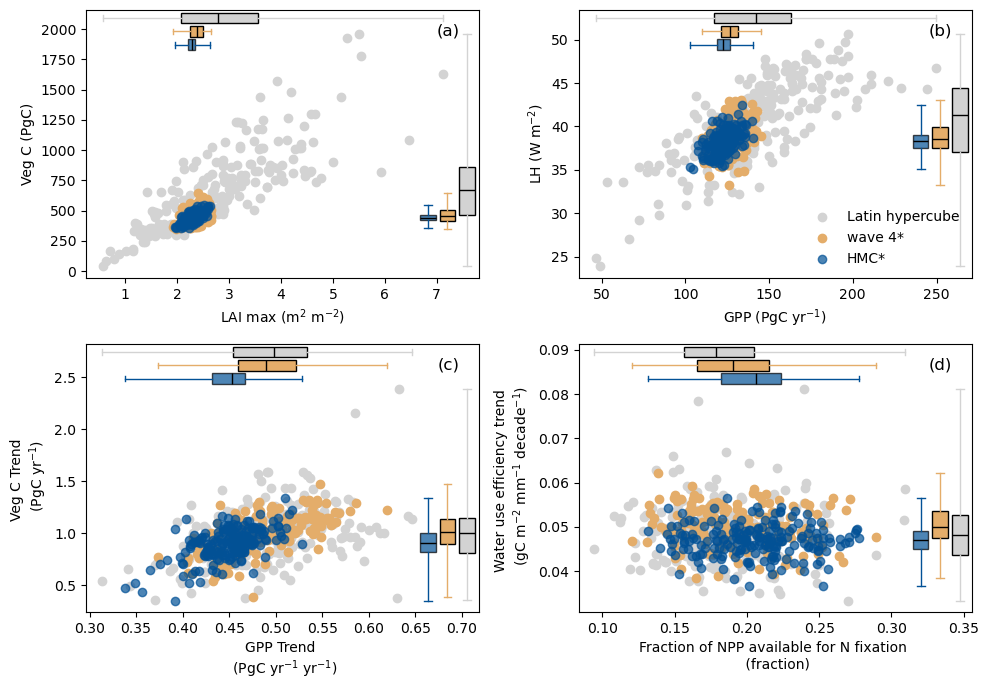

In [22]:
plt.figure(figsize=(10,7))

colors = ['lightgrey','#E4AD6A','#025196']

ax = plt.subplot(2, 2, 1)
ax.scatter(da_lhc.lai,da_lhc.tvc,color='lightgrey',alpha = 1)
ax.scatter(da_w4.lai,da_w4.tvc,color=colors[1],alpha = 1)
ax.scatter(da_hmc.lai,da_hmc.tvc,color=colors[2],alpha = 0.7)
add_marginal_boxplots(ax, da_w4.lai.values, da_w4.tvc.values, da_hmc.lai.values, da_hmc.tvc.values, da_lhc.lai.values, da_lhc.tvc.values, colors, pad=0.05)
ax.set_xlabel('LAI max (m$^{2}$ m$^{-2}$)')
ax.set_ylabel('Veg C (PgC)')
ax.text(0.95, 0.95, '(a)', transform=ax.transAxes, fontsize=12, va='top', ha='right')


ax = plt.subplot(2,2,2)
ax.scatter(1E-9*la.sum()*365*da_lhc.gpp,da_lhc.lh,color='lightgrey',alpha = 1,label='Latin hypercube')
ax.scatter(1E-9*la.sum()*365*da_w4.gpp,da_w4.lh,color=colors[1],alpha = 1,label='wave 4*')
ax.scatter(1E-9*la.sum()*365*da_hmc.gpp,da_hmc.lh,color=colors[2],alpha = 0.7,label='HMC*')
add_marginal_boxplots(ax, (1E-9*la.sum()*365*da_w4.gpp).values, da_w4.lh.values, (1E-9*la.sum()*365*da_hmc.gpp).values, da_hmc.lh.values,  (1E-9*la.sum()*365*da_lhc.gpp).values, da_lhc.lh.values, colors, pad=0.05)
ax.set_xlabel('GPP (PgC yr$^{-1}$)')
ax.set_ylabel('LH (W m$^{-2}$)')
ax.legend(loc='lower right',fontsize=10,frameon=False)
ax.text(0.95, 0.95, '(b)', transform=ax.transAxes, fontsize=12, va='top', ha='right')


ax = plt.subplot(2,2,3)
ax.scatter(gpp_trend_lhc,tvc_trend_lhc,color='lightgrey',alpha = 1)
ax.scatter(gpp_trend_wave4,tvc_trend_wave4,color=colors[1],alpha = 1)
ax.scatter(gpp_trend_hmc,tvc_trend_hmc,color=colors[2],alpha = 0.7)
#ax.set_xlim([0.11,0.40])
add_marginal_boxplots(ax, gpp_trend_wave4.values, tvc_trend_wave4.values, 
                      gpp_trend_hmc.values, tvc_trend_hmc.values, 
                      gpp_trend_lhc.values, tvc_trend_lhc.values,
                      colors,pad=0.15)

ax.set_xlabel('GPP Trend \n (PgC yr$^{-1}$ yr$^{-1}$)')
ax.set_ylabel('Veg C Trend \n (PgC yr$^{-1}$)')
ax.text(0.95, 0.95, '(c)', transform=ax.transAxes, fontsize=12, va='top', ha='right')


ax = plt.subplot(2,2,4)
ax.scatter(ncost_lhc,10*wue_trend_lhc,color='lightgrey',alpha = 1)
ax.scatter(ncost_wave4,10*wue_trend_wave4,color=colors[1],alpha = 1)
ax.scatter(ncost_hmc,10*wue_trend_hmc,color=colors[2],alpha = 0.7)
add_marginal_boxplots(ax, ncost_wave4.values, 10*wue_trend_wave4.values, 
                      ncost_hmc.values, 10*wue_trend_hmc.values, 
                      ncost_lhc.values, 10*wue_trend_lhc.values,
                      colors)
ax.set_xlabel('Fraction of NPP available for N fixation \n (fraction)')
ax.set_ylabel('Water use efficiency trend \n (gC m$^{-2}$ mm$^{-1}$ decade$^{-1}$)')
ax.text(0.95, 0.95, '(d)', transform=ax.transAxes, fontsize=12, va='top', ha='right')


plt.tight_layout()
plt.savefig('../figs/figure8.png',dpi=300)

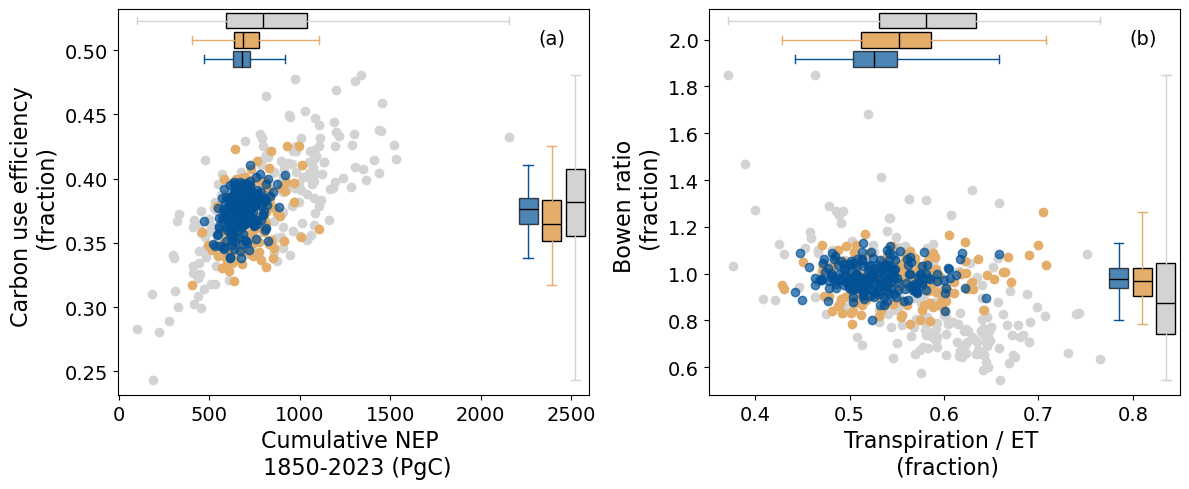

In [27]:
plt.figure(figsize=(12,5))
colors = ['lightgrey','#E4AD6A','#025196']

# Font size settings
LABEL_FS = 16      # axis labels
TICK_FS = 14       # tick labels
PANEL_FS = 14      # panel labels (a, b, c, ...)
LEGEND_FS = 16     # legend

def add_panel_label(ax, label):
    ax.text(0.95, 0.95, label, transform=ax.transAxes,
            fontsize=PANEL_FS,
            ha='right', va='top')

ax = plt.subplot(1,2,1)
ax.scatter(nep_cumu_lhc,cue_lhc,color='lightgrey',alpha = 1)
ax.scatter(nep_cumu_wave4,cue_wave4,color=colors[1],alpha = 1)
ax.scatter(nep_cumu_hmc,cue_hmc,color=colors[2],alpha = 0.7)
add_marginal_boxplots(ax, nep_cumu_wave4.values, cue_wave4.values, 
                      nep_cumu_hmc.values, cue_hmc.values, 
                      nep_cumu_lhc.values, cue_lhc.values,
                      colors)
ax.set_xlabel('Cumulative NEP \n 1850-2023 (PgC)', fontsize=LABEL_FS)
ax.set_ylabel('Carbon use efficiency \n (fraction)', fontsize=LABEL_FS)
ax.tick_params(labelsize=TICK_FS)
add_panel_label(ax, '(a)')

ax = plt.subplot(1,2,2)
ax.scatter(tet_lhc,bowen_lhc,color='lightgrey',alpha = 1)
ax.scatter(tet_wave4,bowen_wave4,color=colors[1],alpha = 1)
ax.scatter(tet_hmc,bowen_hmc,color=colors[2],alpha = 0.7)
add_marginal_boxplots(ax, tet_wave4.values, bowen_wave4.values, 
                      tet_hmc.values, bowen_hmc.values, 
                      tet_lhc.values, bowen_lhc.values,
                      colors)
ax.set_xlabel('Transpiration / ET \n (fraction)', fontsize=LABEL_FS)
ax.set_ylabel('Bowen ratio \n (fraction)', fontsize=LABEL_FS)
ax.tick_params(labelsize=TICK_FS)
add_panel_label(ax, '(b)')

plt.tight_layout()
plt.savefig('../figs/SI_FigS15_scatter.png',dpi=300)